# WebDump run analysis

Analyses an HDF5 run recorded by WebDump (CAEN DT2745, Scope firmware). By default it picks the
**most recent** file in `data/`; set `RUN` below to analyse another one.

Sections: run summary · baselines & noise · event rate & dead time · example events · average pulse ·
charge and amplitude spectra · per-channel occupancy and charge · hit multiplicity · pulse timing.

The waveforms are processed in chunks, so runs much larger than memory are fine.

In [1]:
from scipy.optimize import curve_fit
from scipy.special import erfc, erfcx

In [5]:
from pathlib import Path
import time
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm

# ---- parameters ------------------------------------------------------------------------
DATA_DIR = Path("data_cryo")      # WebDump's recording folder (relative to this notebook)
RUN = "run_20261002_145441.h5"                   # file name, e.g. "run_20261001_130647.h5"; None = most recent run
MAX_EVENTS = None            # analyse only the first N events (None = all)
GATE_NS = (-1600, 24000)       # charge integration window, ns relative to the trigger (clipped to the record)
BASELINE = "run"             # "run": per channel, median of the pre-trigger level over the run (robust to pulses
                             #        that leak into the pre-trigger window of some events)
                             # "pretrigger": per event and channel, median of the samples before PRE_END
                             # "measured": baselines WebDump measured with software triggers at the start (stored in the file)
                             # The "Baseline method" section compares all three.
PRE_END = -200                # end of the pre-trigger window, in samples relative to the trigger
LOG_Y = True                 # log scale for the spectra
CHUNK = 500                  # events per processing chunk (limits memory use)

# ---- plot style ------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 9, "lines.linewidth": 1.5, "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=PALETTE),
})

runs = sorted(DATA_DIR.glob("*.h5"), key=lambda p: p.stat().st_mtime)
if not runs and RUN is None:
    raise FileNotFoundError(f"no .h5 files in {DATA_DIR.resolve()}")
path = DATA_DIR / RUN if RUN else runs[-1]
print(f"{len(runs)} run(s) in {DATA_DIR.resolve()}")
print(f"Analysing: {path.name}")

12 run(s) in /Users/lauranavarro/Documents/PhD/code/CRYOSTAT_digitizer/data_cryo
Analysing: run_20261002_145441.h5


## Run summary

In [6]:
f = h5py.File(path, "r")
A = dict(f.attrs)
wf = f["waveforms"]                                  # (events, channels, samples), raw ADC counts
channels = f["channels"][:]                          # digitizer channel number of each row
n_ev = wf.shape[0] if MAX_EVENTS is None else min(MAX_EVENTS, wf.shape[0])
n_ch, ns = wf.shape[1], wf.shape[2]
dt = float(A["tsample_ns"])
pre = int(A["pretrigger"])
t = (np.arange(ns) - pre) * dt                       # ns from trigger
ts = f["timestamp_ns"][:n_ev]
tid = f["trigger_id"][:n_ev].astype(np.int64)
pol = 1 if A.get("edge", "RISE") == "RISE" else -1   # makes pulses positive below
PC = A["adc_to_volts"] / A["zin_ohm"] * 1e3          # pC per ADC·ns  (Q = ∫V dt / Zin)
meas = np.asarray(A["baselines"], dtype=float)       # baseline per recorded channel
thr = np.asarray(A["thresholds"], float) if A["threshold_mode"] == "Relative" \
    else np.asarray(A["thresholds_board_absolute"], float) - meas
duration = (ts[-1] - ts[0]) / 1e9 if n_ev > 1 else 0.0
n_trig = int(tid[-1] - tid[0] + 1) if n_ev > 1 else n_ev

logic = A["itl_logic"] + (f" ≥ {A['itl_majority']}" if A["itl_logic"] == "Majority" else "")
rows = [
    ("Started", A.get("start_time")),
    ("Board", f"{A['model']} s/n {A['serial']}, {A['fw_type']} firmware {A['fpga_fw']}"),
    ("Events analysed", f"{n_ev:,} (file has {wf.shape[0]:,}; stop reason: {A.get('stop_reason', '?')})"),
    ("Duration", f"{duration:.2f} s → {(n_ev - 1) / duration:,.0f} recorded events/s" if duration else "–"),
    ("Triggers in that time", f"{n_trig:,} (trigger_id) → {n_ev / n_trig:.1%} of triggers recorded"),
    ("Dropped by recorder", f"{A.get('dropped_events', 0)}"),
    ("Record", f"{n_ch} channels × {ns} samples = {ns * dt:.0f} ns, pre-trigger {pre * dt:.0f} ns"),
    ("Trigger", f"{A['trigger_mode']} ({A['trigger_source']}), {logic}, edge {A['edge']}"),
    ("Thresholds", f"{A['threshold_mode']}: {np.unique(A['thresholds']).tolist()} ADC counts"),
    ("Charge scale", f"1 ADC·ns = {PC:.4e} pC  (ADC→V {A['adc_to_volts']:.4e}, Zin {A['zin_ohm']:.0f} Ω, VGA {np.unique(A['vga_gains_db']).tolist()} dB)"),
]
w = max(len(k) for k, _ in rows)
print("\n".join(f"{k:<{w}}  {v}" for k, v in rows))

Started                2026-10-02T14:54:41
Board                  DT2745 s/n 52694, Scope firmware 1.0.257
Events analysed        5,000 (file has 5,000; stop reason: reached 5000 events)
Duration               40.73 s → 123 recorded events/s
Triggers in that time  -15,955,249 (trigger_id) → -0.0% of triggers recorded
Dropped by recorder    0
Record                 64 channels × 3000 samples = 24000 ns, pre-trigger 1600 ns
Trigger                self (ITLA), Majority ≥ 2, edge RISE
Thresholds             Relative: [19] ADC counts
Charge scale           1 ADC·ns = 6.1455e-04 pC  (ADC→V 6.1455e-05, Zin 100 Ω, VGA [1.0] dB)


In [7]:
f['waveforms']

<HDF5 dataset "waveforms": shape (5000, 64, 3000), type "<u2">

## Baselines and noise
Per channel, from the pre-trigger samples of the first 2000 events. Noise is a robust RMS
(1.4826 × median absolute deviation), so occasional pulses in the window don't inflate it.
The right map shows how far this run's pre-trigger level sits from the baseline WebDump measured
when recording started (drift, or signal leaking into the pre-trigger window).

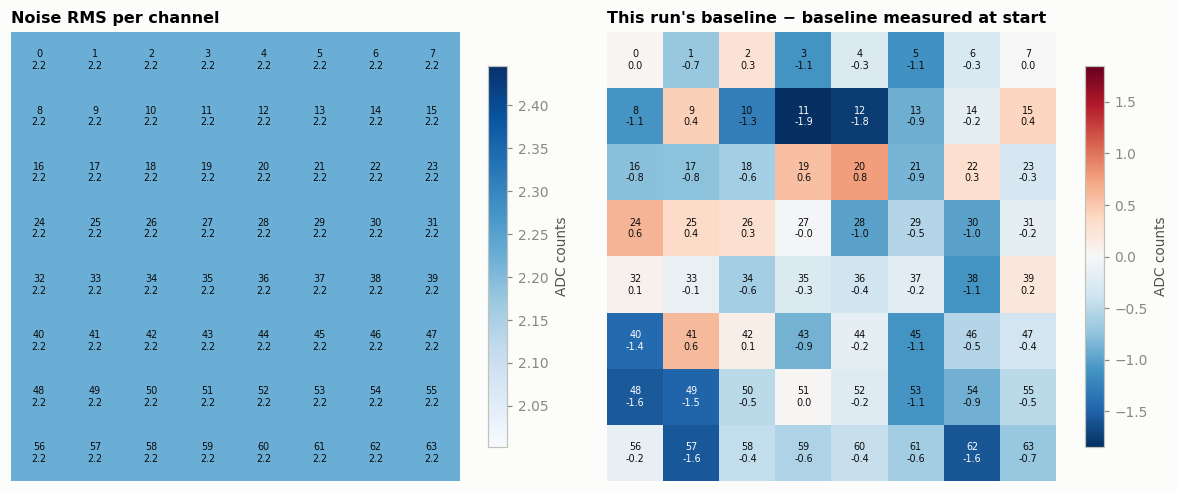

noise: median 2.22, range 2.22–2.22 ADC counts (0.137 mV)
summed over channels, the measured baselines are off by -31.1 ADC counts (→ -458.0 pC over a full record)


In [8]:
def chgrid(values):
    """Place per-recorded-channel values on the 8×8 board layout (NaN where not recorded)."""
    g = np.full(64, np.nan)
    g[channels] = values
    return g.reshape(8, 8)

def heatmap(ax, values, title, label, fmt="{:.1f}", **imshow_kw):
    g = chgrid(values)
    im = ax.imshow(g, **imshow_kw)
    for (r, c), v in np.ndenumerate(g):
        if np.isfinite(v):
            dark = float(im.norm(v)) > 0.6 if imshow_kw.get("cmap") == "Blues" else abs(float(im.norm(v)) - 0.5) > 0.35
            ax.text(c, r, f"{r * 8 + c}\n{fmt.format(v)}", ha="center", va="center", fontsize=6.3,
                    color="white" if dark else INK)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    plt.colorbar(im, ax=ax, label=label, shrink=0.85)

w0 = wf[:min(n_ev, 2000)].astype(np.float32)
win = w0[:, :, :max(4, pre + PRE_END)]
pre_med = np.median(win, axis=2)                                  # per event, per channel
noise = np.median(1.4826 * np.median(np.abs(win - pre_med[..., None]), axis=2), axis=0)
run_base = np.median(win.mean(axis=2), axis=0)                    # per channel: this run's baseline
offset = run_base - meas
del w0, win

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
heatmap(axs[0], noise, "Noise RMS per channel", "ADC counts", cmap="Blues")
lim = max(1.0, np.nanmax(np.abs(offset)))
heatmap(axs[1], offset, "This run's baseline − baseline measured at start", "ADC counts",
        cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
plt.tight_layout(); plt.show()
print(f"noise: median {np.median(noise):.2f}, range {noise.min():.2f}–{noise.max():.2f} ADC counts "
      f"({np.median(noise) * A['adc_to_volts'] * 1e3:.3f} mV)")
print(f"summed over channels, the measured baselines are off by {offset.sum():+.1f} ADC counts "
      f"(→ {offset.sum() * (ns * dt) * PC:+.1f} pC over a full record)")

## Feature extraction
One pass over all events. Per event and channel: amplitude (maximum after baseline subtraction,
pulses made positive), peak sample and charge in the gate; the same for the sum of all channels.

In [9]:
g0 = int(np.clip(pre + round(GATE_NS[0] / dt), 0, ns - 1))
g1 = int(np.clip(pre + round(GATE_NS[1] / dt), g0 + 1, ns))
pe = max(4, pre + PRE_END)                     # end of the pre-trigger window (samples)

amp = np.empty((n_ev, n_ch), np.float32)       # ADC counts
peak = np.empty((n_ev, n_ch), np.int16)        # sample index
q = np.empty((n_ev, n_ch), np.float32)         # pC
sum_amp = np.empty(n_ev, np.float32)
sum_peak = np.empty(n_ev, np.int16)
sum_q = np.empty(n_ev, np.float32)
pre_pulse = np.empty(n_ev, bool)               # some channel crossed its threshold before the trigger window
gate_raw = np.empty(n_ev, np.float64)          # raw summed gate integral, to compare baseline methods
ev_base_sum = np.empty(n_ev, np.float64)       # per-event baseline summed over channels
pre_level = np.empty(n_ev, np.float64)         # mean of the summed pre-trigger window (run baseline)
mean_wf = np.zeros((n_ch, ns))
examples = None

t_start = time.time()
for a in range(0, n_ev, CHUNK):
    b = min(n_ev, a + CHUNK)
    x = wf[a:b].astype(np.float32)
    ev_base = np.median(x[:, :, :pe], axis=2)
    gate_raw[a:b] = x[:, :, g0:g1].sum(axis=(1, 2), dtype=np.float64)
    ev_base_sum[a:b] = ev_base.sum(axis=1)
    xp = (x[:, :, :pe] - run_base[None, :, None]) * pol
    pre_level[a:b] = xp.sum(axis=1).mean(axis=1) * pol
    pre_pulse[a:b] = (xp.max(axis=2) > thr[None, :] * pol).any(axis=1)
    base = {"measured": meas[None, :, None], "run": run_base[None, :, None],
            "pretrigger": ev_base[..., None]}[BASELINE]
    x = (x - base) * pol
    s = x.sum(axis=1)
    amp[a:b] = x.max(axis=2)
    peak[a:b] = x.argmax(axis=2)
    q[a:b] = x[:, :, g0:g1].sum(axis=2) * dt * PC
    sum_amp[a:b] = s.max(axis=1)
    sum_peak[a:b] = s.argmax(axis=1)
    sum_q[a:b] = s[:, g0:g1].sum(axis=1) * dt * PC
    mean_wf += x.sum(axis=0)
    if examples is None:
        examples = (x[:16].copy(), s[:16].copy())
mean_wf /= n_ev
mean_sum = mean_wf.sum(axis=0)

hits = amp > thr[None, :] * pol                # channel above its trigger threshold
mult = hits.sum(axis=1)
clean = ~pre_pulse                             # no channel above threshold in the pre-trigger window
print(f"{n_ev:,} events in {time.time() - t_start:.1f} s · gate samples {g0}–{g1} "
      f"({t[g0]:.0f} … {t[g1 - 1] + dt:.0f} ns) · baseline: {BASELINE}")
print(f"{pre_pulse.mean():.1%} of events have a channel above threshold inside the pre-trigger window "
      f"(pulse started early relative to the trigger, or pile-up)")

5,000 events in 5.3 s · gate samples 0–3000 (-1600 … 22400 ns) · baseline: run
3.0% of events have a channel above threshold inside the pre-trigger window (pulse started early relative to the trigger, or pile-up)


## Baseline method
The summed charge is very sensitive to the baseline: an offset of 1 ADC count in each of 64
channels becomes 64 counts on the sum, integrated over the whole gate. Left: the summed
pre-trigger level from event to event, compared with what independent channel noise would give;
a much wider distribution means the channels' baselines move **together** (common-mode noise or
slow baseline wander), which per-event baseline subtraction removes. Right: the charge spectrum
with each method.

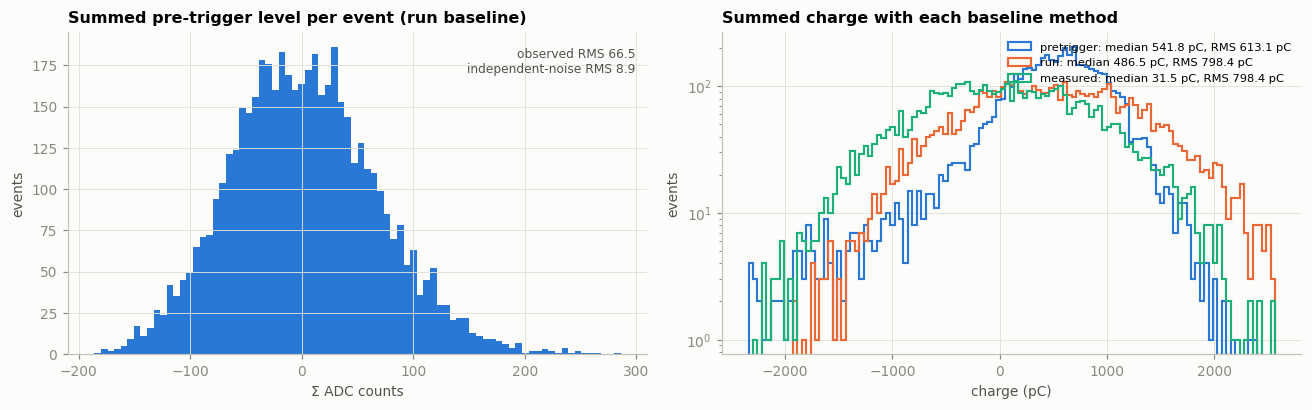

summed baseline fluctuates 7.5× more than independent noise would explain


In [10]:
ng = g1 - g0
q_by = {
    "pretrigger": (gate_raw - ng * ev_base_sum) * dt * PC,
    "run": (gate_raw - ng * run_base.sum()) * dt * PC,
    "measured": (gate_raw - ng * meas.sum()) * dt * PC,
}
expected = np.sqrt(np.sum(noise ** 2) / pe)    # RMS of the summed pre-trigger mean if channels were independent

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(pre_level, bins=80, color=PALETTE[0])
axs[0].set(title="Summed pre-trigger level per event (run baseline)", xlabel="Σ ADC counts", ylabel="events")
axs[0].text(0.98, 0.95, f"observed RMS {pre_level.std():.1f}\nindependent-noise RMS {expected:.1f}",
            transform=axs[0].transAxes, ha="right", va="top", color=INK2, fontsize=8)

lo, hi = np.percentile(np.concatenate(list(q_by.values())), [0.1, 99.9])
bins = np.linspace(lo, hi, 120)
for (name, v), c in zip(q_by.items(), PALETTE):
    axs[1].hist(v, bins=bins, histtype="step", lw=1.4, color=c,
                label=f"{name}: median {np.median(v):.1f} pC, RMS {v.std():.1f} pC")
axs[1].set(title="Summed charge with each baseline method", xlabel="charge (pC)", ylabel="events",
           yscale="log" if LOG_Y else "linear")
axs[1].legend(loc="upper right", fontsize=7.5)
plt.tight_layout(); plt.show()
print(f"summed baseline fluctuates {pre_level.std() / expected:.1f}× more than independent noise would explain")

## Event rate and dead time
`trigger_id` counts every trigger the board saw, so gaps between consecutive recorded events are
triggers that were not recorded (board busy reading out, or the link saturated).

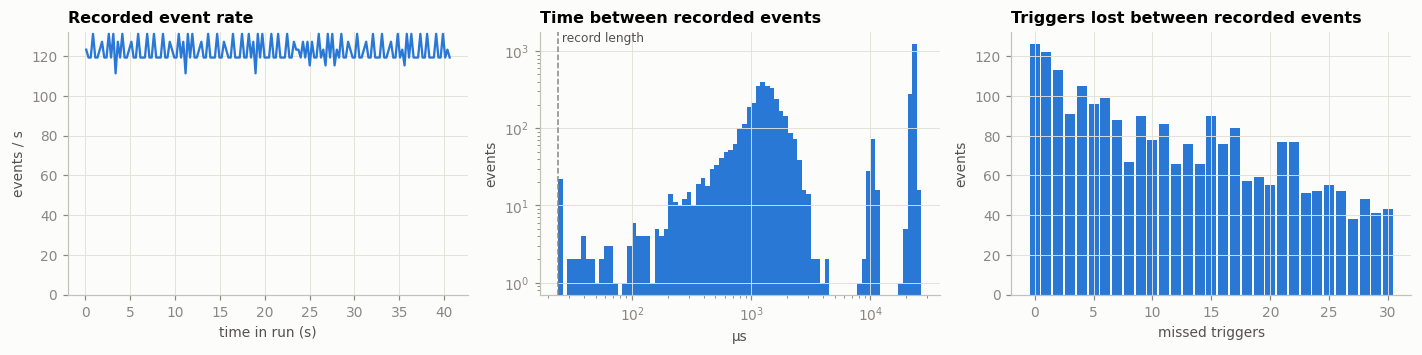

shortest interval 24.01 µs; 97.5% of intervals contain missed triggers (-15,960,249 triggers not recorded)


In [11]:
tsec = (ts - ts[0]) / 1e9
gaps = np.diff(tid) - 1
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3))

nb = max(10, min(200, int(tsec[-1] / 0.25))) if n_ev > 1 else 10
cnt, e = np.histogram(tsec, nb)
axs[0].plot((e[:-1] + e[1:]) / 2, cnt / np.diff(e), color=PALETTE[0])
axs[0].set(title="Recorded event rate", xlabel="time in run (s)", ylabel="events / s", ylim=(0, None))

d_us = np.diff(ts) / 1e3
axs[1].hist(d_us, bins=np.logspace(np.log10(max(d_us.min(), 1e-2)), np.log10(d_us.max()), 80), color=PALETTE[0])
axs[1].set(title="Time between recorded events", xlabel="µs", ylabel="events", xscale="log", yscale="log")
axs[1].axvline(ns * dt / 1e3, color=MUTED, ls="--", lw=1)
axs[1].text(ns * dt / 1e3, axs[1].get_ylim()[1], " record length", color=INK2, va="top", fontsize=8)

axs[2].hist(gaps, bins=np.arange(-0.5, min(gaps.max(), 30) + 1.5), color=PALETTE[0], rwidth=0.85)
axs[2].set(title="Triggers lost between recorded events", xlabel="missed triggers", ylabel="events")
plt.tight_layout(); plt.show()
print(f"shortest interval {d_us.min():.2f} µs; {(gaps > 0).mean():.1%} of intervals contain missed triggers "
      f"({gaps.sum():,} triggers not recorded)")

## Example events
Top: all channels (grey) for one event; bottom: their sum. Shaded: charge gate. Dashed: trigger.

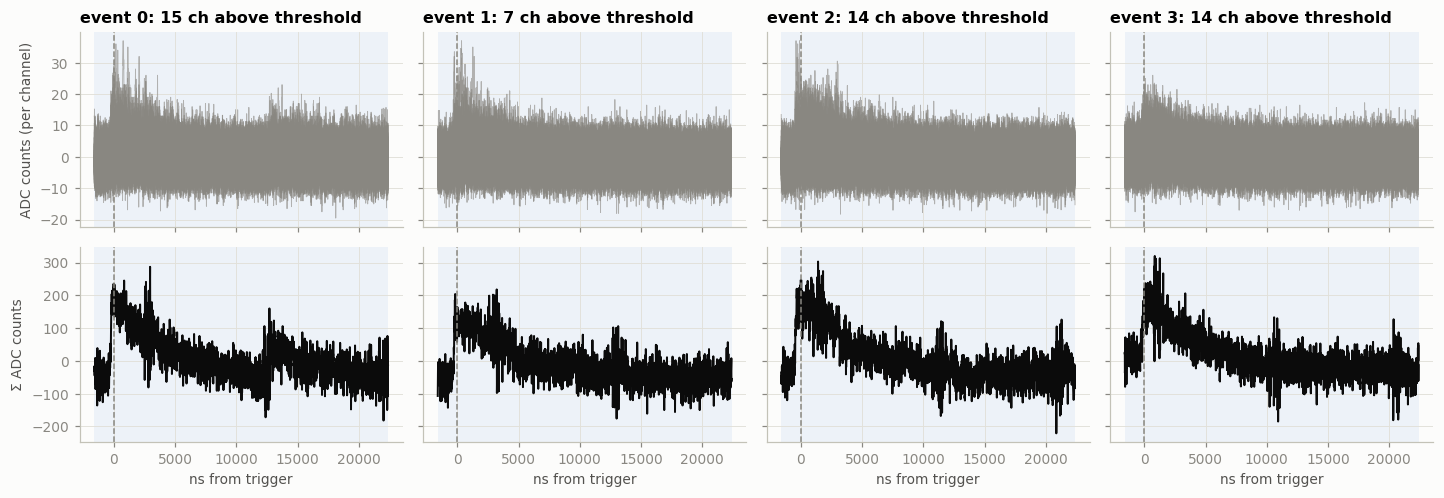

In [12]:
xs, ss = examples
k = min(4, len(xs))
fig, axs = plt.subplots(2, k, figsize=(3.3 * k, 4.6), sharex=True, sharey="row", squeeze=False)
for j in range(k):
    ax = axs[0, j]
    ax.plot(t, xs[j].T, color=MUTED, lw=0.6, alpha=0.6)
    ax.set_title(f"event {j}: {hits[j].sum()} ch above threshold")
    axs[1, j].plot(t, ss[j], color=INK, lw=1.3)
    axs[1, j].set_xlabel("ns from trigger")
    for ax in axs[:, j]:
        ax.axvspan(t[g0], t[g1 - 1] + dt, color=PALETTE[0], alpha=0.07, lw=0)
        ax.axvline(0, color=MUTED, ls="--", lw=1)
axs[0, 0].set_ylabel("ADC counts (per channel)")
axs[1, 0].set_ylabel("Σ ADC counts")
plt.tight_layout(); plt.show()

## Average pulse
Mean baseline-subtracted waveform: sum of all channels, and each channel on the board layout.

##### No fit

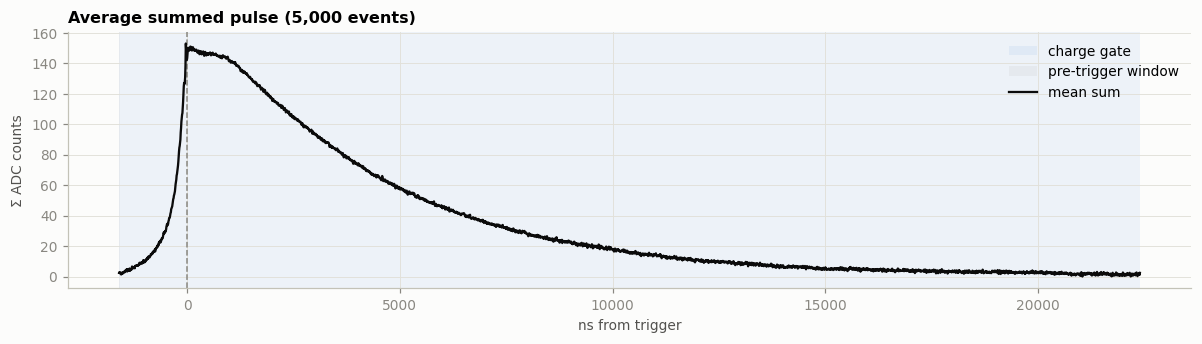

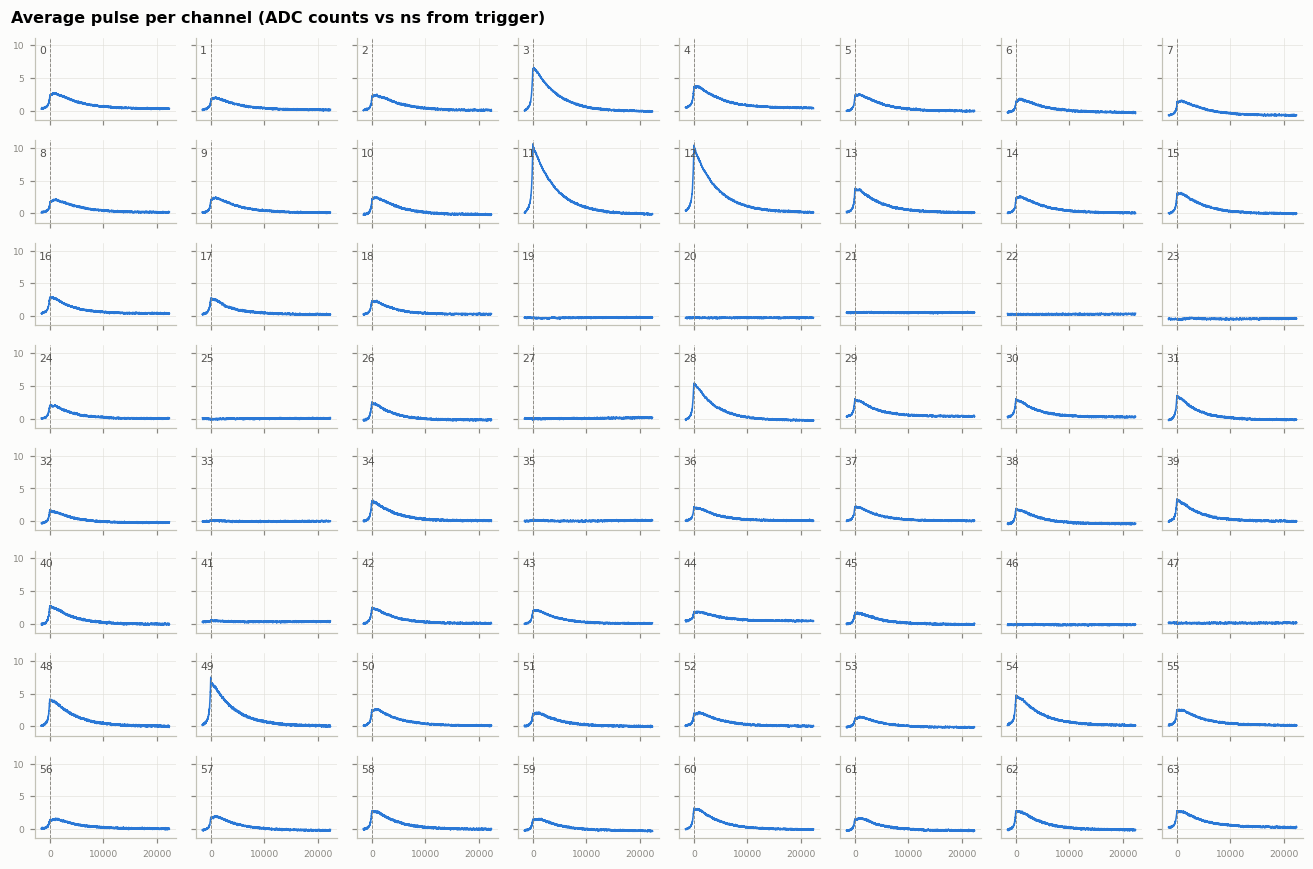

In [13]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axvspan(t[g0], t[g1 - 1] + dt, color=PALETTE[0], alpha=0.07, lw=0, label="charge gate")
ax.axvspan(t[0], t[pe - 1], color=MUTED, alpha=0.08, lw=0, label="pre-trigger window")
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.plot(t, mean_sum, color=INK, label="mean sum")
ax.set(title=f"Average summed pulse ({n_ev:,} events)", xlabel="ns from trigger", ylabel="Σ ADC counts")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

full = np.full((64, ns), np.nan); full[channels] = mean_wf
fig, axs = plt.subplots(8, 8, figsize=(12, 8), sharex=True, sharey=True)
for ch, ax in enumerate(axs.flat):
    ax.plot(t, full[ch], color=PALETTE[0], lw=1)
    ax.axvline(0, color=MUTED, ls="--", lw=0.6)
    ax.text(0.03, 0.9, f"{ch}", transform=ax.transAxes, fontsize=7, color=INK2, va="top")
    ax.tick_params(labelsize=6); ax.grid(lw=0.4)
fig.suptitle("Average pulse per channel (ADC counts vs ns from trigger)", x=0.01, ha="left", fontweight="bold", fontsize=10.5)
plt.tight_layout(); plt.show()

## Charge and amplitude spectra (sum of all channels)
"All events" vs "clean" events: no channel above its threshold in the pre-trigger window. Events
fail this when a pulse started well before the trigger fired (slow rise, late trigger) or when a
second pulse piles up; see *Average pulse* and *Timing*.

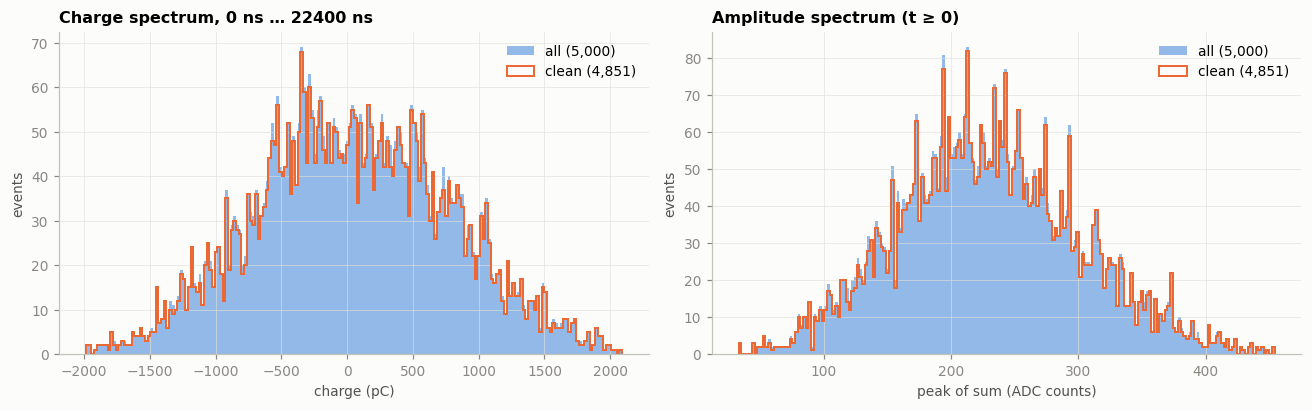

In [20]:
# --- sum over channels, integrated from t = 0 to end of record ---
i0 = pre                                   # sample index of t = 0
q0   = np.empty(n_ev)                      # charge, pC
amp0 = np.empty(n_ev)                      # peak of the summed waveform, ADC counts
CH = 2000                                  # events per read chunk

for a in range(0, n_ev, CH):
    b = min(a + CH, n_ev)
    blk = wf[a:b, :, i0:].astype(np.float32)          # only post-trigger samples are read from disk
    blk = (blk - meas[None, :, None]) * pol           # baseline-subtract, positive pulses
    s = blk.sum(axis=1)                               # (chunk, ns - i0) summed waveform
    q0[a:b]   = s.sum(axis=1, dtype=np.float64) * dt * PC
    amp0[a:b] = s.max(axis=1)

# --- plot ---
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))

for ax, v, xlabel, title in [
    (axs[0], q0,   "charge (pC)",              f"Charge spectrum, 0 ns … {t[-1] + dt:.0f} ns"),
    (axs[1], amp0, "peak of sum (ADC counts)", "Amplitude spectrum (t ≥ 0)"),
]:
    rng = tuple(np.percentile(v, [0.2, 99.8]))        # ignore extreme outliers in the plot range
    ax.hist(v, bins=200, range=rng, color=PALETTE[0], alpha=0.5, label=f"all ({len(v):,})")
    ax.hist(v[clean], bins=200, range=rng, histtype="step", color=PALETTE[1], lw=1.3,
            label=f"clean ({clean.sum():,})")
    ax.set(title=title, xlabel=xlabel, ylabel="events")
    ax.grid(lw=0.4)
    ax.legend(loc="upper right")

plt.tight_layout(); plt.show()

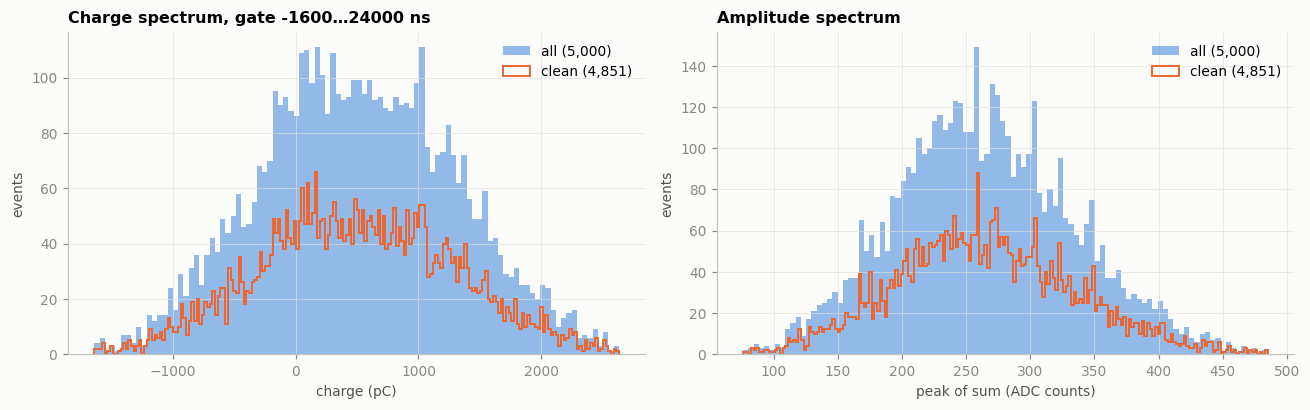

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))

for ax, v, xlabel, title in [
    (axs[0], sum_q,   "charge (pC)",            f"Charge spectrum, gate {GATE_NS[0]}…{GATE_NS[1]} ns"),
    (axs[1], sum_amp, "peak of sum (ADC counts)", "Amplitude spectrum"),
]:
    rng = tuple(np.percentile(v, [0.2, 99.8]))          # ignore extreme outliers in the plot range
    ax.hist(v, bins=100, range=rng, color=PALETTE[0], alpha=0.5, label=f"all ({len(v):,})")
    ax.hist(v[clean], bins=200, range=rng, histtype="step", color=PALETTE[1], lw=1.3,
            label=f"clean ({clean.sum():,})")
    ax.set(title=title, xlabel=xlabel, ylabel="events")  # linear y by default
    ax.grid(lw=0.4)
    ax.legend(loc="upper right")

plt.tight_layout(); plt.show()

charge     μ = 495.7 ± 14 pC | σ = 815.9 ± 13 pC | FWHM = 1921 pC | resolution = 387.63% ± 12.42% | χ²/ndf = 1.23
amplitude  μ = 261.3 ± 1.2 ADC | σ = 68.49 ± 1.2 ADC | FWHM = 161.3 ADC | resolution = 61.71% ± 1.06% | χ²/ndf = 1.36


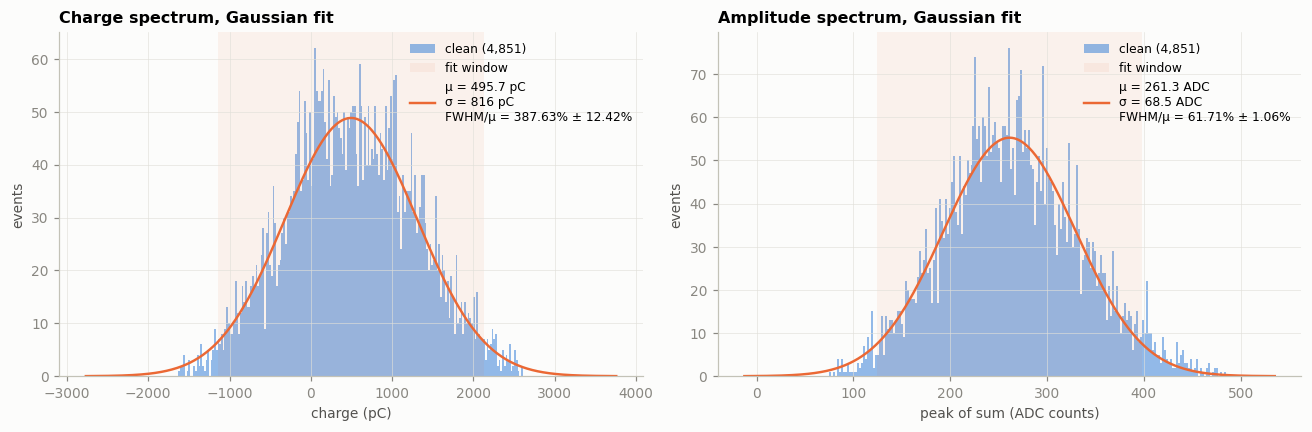

In [22]:
def gauss(x, N, mu, sig):
    return N * np.exp(-0.5 * ((x - mu) / sig) ** 2)

# optional: restrict the peak search if there is a pedestal/noise peak or a second line, e.g. (50, 400)
PEAK_RANGE = {"charge": None, "amplitude": None}

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
results = {}

for ax, key, v, xlabel, unit in [
    (axs[0], "charge",    sum_q[clean],   "charge (pC)",              "pC"),
    (axs[1], "amplitude", sum_amp[clean], "peak of sum (ADC counts)", "ADC"),
]:
    rng = tuple(np.percentile(v, [0.2, 99.8]))
    cnt, edges = np.histogram(v, bins=200, range=rng)
    xc = 0.5 * (edges[:-1] + edges[1:])

    # --- initial guess: tallest bin of a lightly smoothed histogram ---
    sm = np.convolve(cnt, np.ones(5) / 5, mode="same")
    sel = np.ones_like(xc, bool) if PEAK_RANGE[key] is None else (xc >= PEAK_RANGE[key][0]) & (xc <= PEAK_RANGE[key][1])
    ipk = np.argmax(np.where(sel, sm, -np.inf))
    mu0 = xc[ipk]
    half = np.where(sm[ipk:] < sm[ipk] / 2)[0]
    sig0 = (xc[ipk + half[0]] - mu0) / 1.1774 if len(half) else (rng[1] - rng[0]) / 20
    p = [cnt[ipk], mu0, max(sig0, edges[1] - edges[0])]

    # --- iterative fit: refit in mu ± 2σ until it settles ---
    for _ in range(5):
        m = (xc > p[1] - 2 * abs(p[2])) & (xc < p[1] + 2 * abs(p[2])) & (cnt > 0)
        p, pcov = curve_fit(gauss, xc[m], cnt[m], p0=p, sigma=np.sqrt(cnt[m]), absolute_sigma=True)
    N_, mu_, sig_ = p[0], p[1], abs(p[2])
    perr = np.sqrt(np.diag(pcov))

    # --- resolution = FWHM / mu, with error propagation including covariance ---
    R = 2.3548 * sig_ / mu_
    rel = np.sqrt((perr[2] / sig_) ** 2 + (perr[1] / mu_) ** 2 - 2 * pcov[1, 2] / (mu_ * sig_))
    dR = R * rel
    chi2 = np.sum((cnt[m] - gauss(xc[m], *p)) ** 2 / cnt[m]) / (m.sum() - 3)
    results[key] = (mu_, sig_, R, dR)

    # --- plot ---
    xx = np.linspace(mu_ - 4 * sig_, mu_ + 4 * sig_, 500)
    ax.hist(v, bins=200, range=rng, color=PALETTE[0], alpha=0.5, label=f"clean ({len(v):,})")
    ax.axvspan(mu_ - 2 * sig_, mu_ + 2 * sig_, color=PALETTE[1], alpha=0.07, lw=0, label="fit window")
    ax.plot(xx, gauss(xx, *p), color=PALETTE[1], lw=1.6,
            label=f"μ = {mu_:.4g} {unit}\nσ = {sig_:.3g} {unit}\nFWHM/μ = {R:.2%} ± {dR:.2%}")
    ax.set(title=f"{key.capitalize()} spectrum, Gaussian fit", xlabel=xlabel, ylabel="events")
    ax.grid(lw=0.4); ax.legend(loc="upper right", fontsize=8)

    print(f"{key:<10} μ = {mu_:.4g} ± {perr[1]:.2g} {unit} | σ = {sig_:.4g} ± {perr[2]:.2g} {unit} | "
          f"FWHM = {2.3548 * sig_:.4g} {unit} | resolution = {R:.2%} ± {dR:.2%} | χ²/ndf = {chi2:.2f}")

plt.tight_layout(); plt.show()

##### Plot function

In [23]:
def spectrum(ax, v, sel, title, xlabel, unit):
    lo, hi = np.percentile(v, [0.2, 99.8])
    pad = 0.05 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    bins = np.histogram_bin_edges(v[(v >= lo) & (v <= hi)], bins="fd")
    if len(bins) > 301:
        bins = np.linspace(lo, hi, 300)
    out = int(((v < lo) | (v > hi)).sum())
    if out:
        ax.text(0.98, 0.45, f"{out} events outside the plotted range", transform=ax.transAxes,
                ha="right", va="top", color=MUTED, fontsize=7.5)
    ax.hist(v, bins=bins, histtype="stepfilled", color=PALETTE[0], alpha=0.35, lw=0)
    ax.hist(v, bins=bins, histtype="step", color=PALETTE[0], lw=1.3, label=f"all ({len(v):,})")
    ax.hist(v[sel], bins=bins, histtype="step", color=PALETTE[1], lw=1.3, label=f"clean ({sel.sum():,})")
    ax.set(title=title, xlabel=xlabel, ylabel="events", yscale="log" if LOG_Y else "linear")
    ax.legend(loc="upper right")
    ax.text(0.98, 0.72, f"mean {v.mean():.4g} {unit}\nmedian {np.median(v):.4g} {unit}\nRMS {v.std():.4g} {unit}",
            transform=ax.transAxes, ha="right", va="top", color=INK2, fontsize=8)

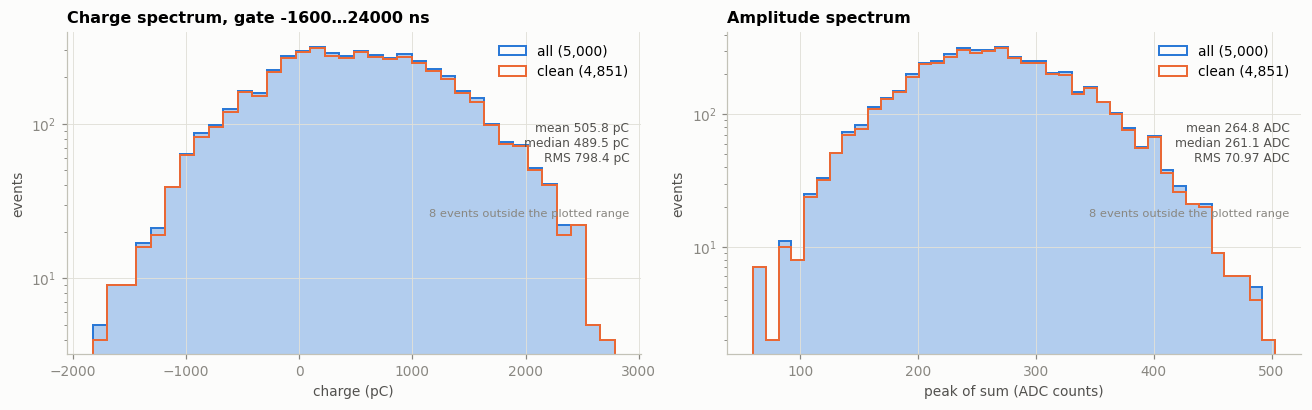

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
spectrum(axs[0], sum_q, clean, f"Charge spectrum, gate {GATE_NS[0]}…{GATE_NS[1]} ns", "charge (pC)", "pC")
spectrum(axs[1], sum_amp, clean, "Amplitude spectrum", "peak of sum (ADC counts)", "ADC")
plt.tight_layout(); plt.show()

## Per channel
Occupancy = fraction of events in which the channel is above its trigger threshold.

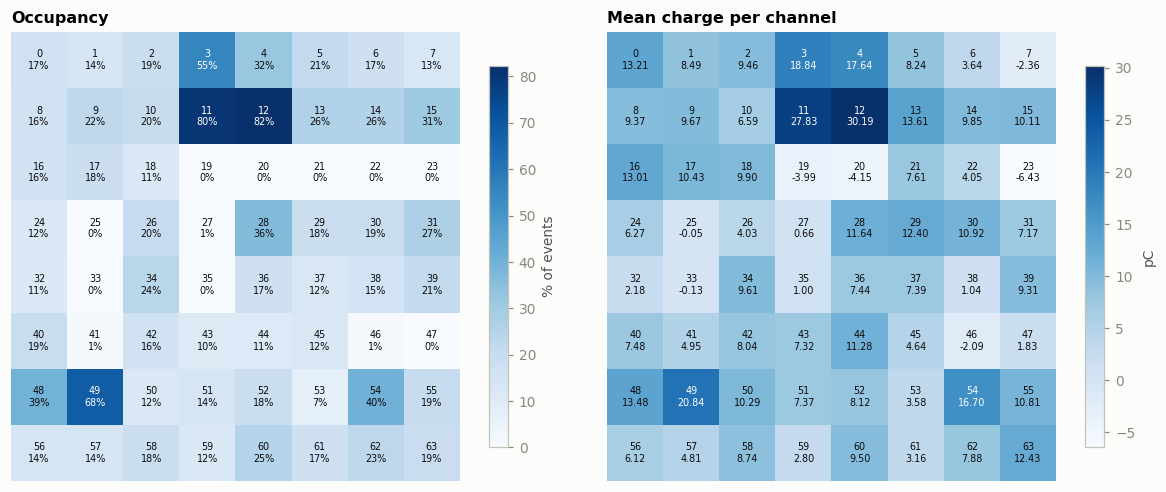

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
heatmap(axs[0], hits.mean(axis=0) * 100, "Occupancy", "% of events", fmt="{:.0f}%", cmap="Blues", vmin=0)
heatmap(axs[1], q.mean(axis=0), "Mean charge per channel", "pC", fmt="{:.2f}", cmap="Blues")
plt.tight_layout(); plt.show()

## Hit multiplicity
Number of channels above threshold per event, and how the summed charge grows with it.

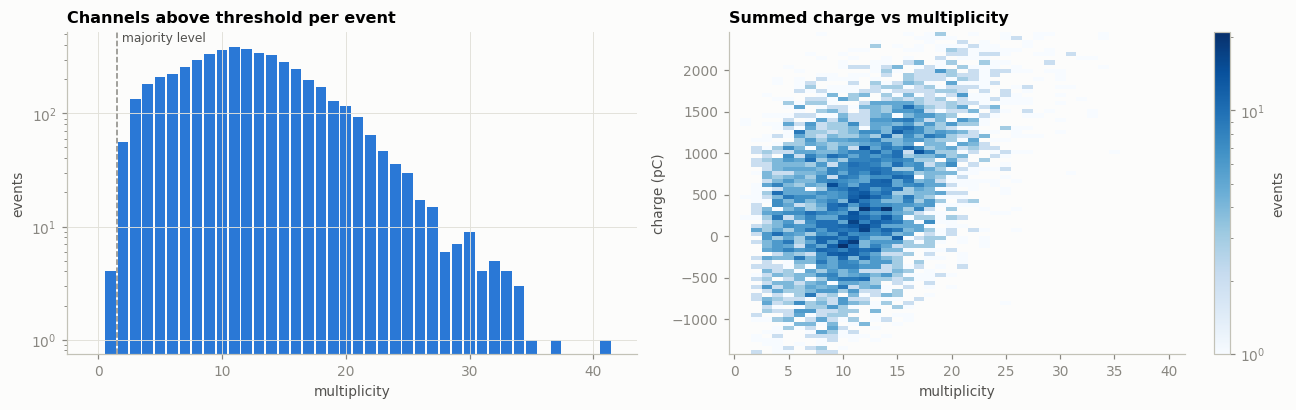

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
mb = np.arange(-0.5, mult.max() + 1.5)
axs[0].hist(mult, bins=mb, color=PALETTE[0], rwidth=0.85)
axs[0].set(title="Channels above threshold per event", xlabel="multiplicity", ylabel="events",
           yscale="log" if LOG_Y else "linear")
if A["itl_logic"] == "Majority":
    axs[0].axvline(A["itl_majority"] - 0.5, color=MUTED, ls="--", lw=1)
    axs[0].text(A["itl_majority"] - 0.4, axs[0].get_ylim()[1], " majority level", color=INK2, va="top", fontsize=8)

lo, hi = np.percentile(sum_q, [0.5, 99.5])
h = axs[1].hist2d(mult, sum_q, bins=[mb, np.linspace(lo, hi, 80)], cmap="Blues", norm=LogNorm(), cmin=1)
plt.colorbar(h[3], ax=axs[1], label="events")
axs[1].set(title="Summed charge vs multiplicity", xlabel="multiplicity", ylabel="charge (pC)")
axs[1].grid(False)
plt.tight_layout(); plt.show()

## Timing
Where the summed pulse peaks relative to the trigger, and how spread out the channels' peaks are within an event.

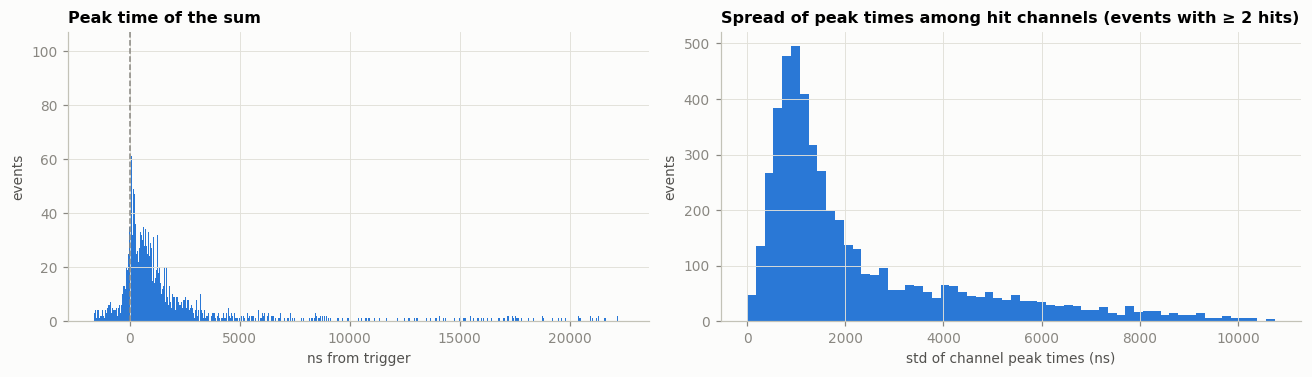

sum peak time: median 776 ns; channel peak-time spread: median 1417 ns


In [27]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].hist(t[sum_peak], bins=np.arange(t[0], t[-1] + dt, dt * 2), color=PALETTE[0])
axs[0].axvline(0, color=MUTED, ls="--", lw=1)
axs[0].set(title="Peak time of the sum", xlabel="ns from trigger", ylabel="events")

pt = np.where(hits, t[peak], np.nan)
spread = np.nanstd(pt[mult >= 2], axis=1)
axs[1].hist(spread, bins=60, color=PALETTE[0])
axs[1].set(title="Spread of peak times among hit channels (events with ≥ 2 hits)",
           xlabel="std of channel peak times (ns)", ylabel="events")
plt.tight_layout(); plt.show()
print(f"sum peak time: median {np.median(t[sum_peak]):.0f} ns; channel peak-time spread: median {np.nanmedian(spread):.0f} ns")

## Notes
- **Baseline choice.** `"run"` (default) uses one baseline per channel taken from this run's data.
  `"pretrigger"` (per event) follows baseline movements shared by the channels, but is badly
  biased whenever a pulse starts inside the pre-trigger window (negative charges in the spectrum).
  `"measured"` uses the values stored at the start of recording and is off if baselines drifted.
  The *Baseline method* section shows how much this matters for the run; a longer pre-trigger
  gives the per-event method more clean samples.
- **Gate.** Set `GATE_NS` to cover the whole pulse (see *Average pulse*); the record length limits
  how much of a long tail can be integrated.
- **Pre-trigger.** If the average pulse starts rising inside the pre-trigger window, the trigger fires
  late relative to the pulse start; a longer pre-trigger (in WebDump) keeps the baseline region clean.
- **Dead channels.** Channels with ~0% occupancy and a flat average pulse are probably unconnected.
- **Recorded fraction.** If many triggers are missed (see *Event rate and dead time*), the board was
  busy or the link was saturated: shorter records, fewer channels or a higher threshold reduce that.
- The file stays open as `f` for interactive exploration: e.g. `f["waveforms"][123]` is one event.